# Задание для нечетных вариантов: Градиентный бустинг

## 1. Импорт библиотек

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style('whitegrid')


## 2. Загрузка и анализ данных


In [ ]:
# Загрузка датасета
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print(f'Размер датасета: {df.shape}')
print(f'Признаки: {list(data.feature_names)}')
print(f'\nКлассы: {dict(enumerate(data.target_names))}')
df.head()

In [ ]:
# Общая информация
print('=== Информация о датасете ===')
df.info()
print('\n=== Пропущенные значения ===')
print(df.isnull().sum().sum(), '(нет пропусков)')

In [ ]:
# Статистика по признакам
df.describe().round(3)

In [ ]:
# Распределение классов
class_counts = df['target'].value_counts()
print('Распределение классов:')
print(f'  Злокачественная (0): {class_counts[0]} ({class_counts[0]/len(df)*100:.1f}%)')
print(f'  Доброкачественная (1): {class_counts[1]} ({class_counts[1]/len(df)*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Анализ датасета Breast Cancer', fontsize=14, fontweight='bold')

# Круговая диаграмма
axes[0].pie(
    class_counts.values,
    labels=['Доброкачественная (1)', 'Злокачественная (0)'],
    autopct='%1.1f%%',
    colors=['#4CAF50', '#F44336'],
    startangle=140,
    explode=(0.05, 0)
)
axes[0].set_title('Распределение классов')

# Тепловая карта корреляции топ-10 признаков
top_features = df.corr()['target'].abs().nlargest(11).index[1:]
sns.heatmap(
    df[top_features].corr(), ax=axes[1],
    annot=True, fmt='.2f', cmap='coolwarm',
    linewidths=0.5, annot_kws={'size': 7}
)
axes[1].set_title('Корреляция топ-10 признаков')
axes[1].tick_params(axis='x', rotation=45, labelsize=7)
axes[1].tick_params(axis='y', rotation=0, labelsize=7)

plt.tight_layout()
plt.show()

In [ ]:
# Распределение ключевых признаков по классам
key_features = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean concavity']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('Распределение признаков по классам', fontsize=13, fontweight='bold')

for ax, feat in zip(axes.flatten(), key_features):
    for cls, color, label in [(0, '#F44336', 'Злокачественная'), (1, '#4CAF50', 'Доброкачественная')]:
        ax.hist(
            df[df['target'] == cls][feat],
            bins=25, alpha=0.6, color=color, label=label, edgecolor='white'
        )
    ax.set_title(feat, fontsize=10)
    ax.set_xlabel('Значение')
    ax.set_ylabel('Частота')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 3. Предобработка данных

In [ ]:
# Разделение на X и y
X = df.drop('target', axis=1)
y = df['target']

# Разбиение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Тренировочная выборка: {X_train.shape[0]} образцов')
print(f'Тестовая выборка:      {X_test.shape[0]} образцов')
print(f'\nРаспределение классов в train: {dict(y_train.value_counts())}')
print(f'Распределение классов в test:  {dict(y_test.value_counts())}')

In [ ]:
# Стандартизация
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print('StandardScaler применён ✓')
print(f'Среднее (train после масштабирования): {X_train_sc.mean():.6f}')
print(f'Std    (train после масштабирования):  {X_train_sc.std():.6f}')

# Визуализация до/после нормализации
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Эффект стандартизации (mean radius)', fontsize=13, fontweight='bold')

axes[0].hist(X_train['mean radius'], bins=30, color='#90CAF9', edgecolor='white')
axes[0].set_title('До стандартизации')
axes[0].set_xlabel('Значение')

col_idx = list(X.columns).index('mean radius')
axes[1].hist(X_train_sc[:, col_idx], bins=30, color='#1565C0', edgecolor='white')
axes[1].set_title('После стандартизации')
axes[1].set_xlabel('Значение (z-score)')

plt.tight_layout()
plt.show()

## 4. Базовая модель градиентного бустинга

In [ ]:
# Базовая модель
gb_base = GradientBoostingClassifier(random_state=42)
gb_base.fit(X_train_sc, y_train)

print('Параметры базовой модели:')
for k, v in gb_base.get_params().items():
    print(f'  {k}: {v}')

In [ ]:
# Прогнозы и метрики
y_pred_base = gb_base.predict(X_test_sc)

acc_base  = accuracy_score(y_test, y_pred_base)
prec_base = precision_score(y_test, y_pred_base)
rec_base  = recall_score(y_test, y_pred_base)
f1_base   = f1_score(y_test, y_pred_base)

print('=== Метрики базовой модели ===')
print(f'  Accuracy:  {acc_base:.4f}')
print(f'  Precision: {prec_base:.4f}')
print(f'  Recall:    {rec_base:.4f}')
print(f'  F1-score:  {f1_base:.4f}')
print()
print(classification_report(y_test, y_pred_base, target_names=['Злокачественная', 'Доброкачественная']))

In [ ]:
# Матрица ошибок + кривая обучения базовой модели
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Базовая модель градиентного бустинга', fontsize=14, fontweight='bold')

# Матрица ошибок
cm_base = confusion_matrix(y_test, y_pred_base)
ConfusionMatrixDisplay(cm_base, display_labels=['Злокач.', 'Доброкач.']).plot(
    ax=axes[0], colorbar=False, cmap='Blues'
)
axes[0].set_title('Матрица ошибок (базовая модель)')

# Метрики
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
values  = [acc_base, prec_base, rec_base, f1_base]
colors  = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']
bars = axes[1].bar(metrics, values, color=colors, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, values):
    axes[1].text(
        bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
        f'{val:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold'
    )
axes[1].set_ylim(0, 1.1)
axes[1].set_title('Метрики качества базовой модели')
axes[1].set_ylabel('Значение')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Кривая потерь на обучении
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(gb_base.train_score_, color='#1565C0', linewidth=2, label='Train loss')
ax.set_xlabel('Итерация (число деревьев)')
ax.set_ylabel('Deviance (loss)')
ax.set_title('Кривая потерь базовой модели при обучении')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Настройка гиперпараметров (GridSearchCV)

In [13]:
param_grid = {
    'n_estimators':  [50, 100, 200],
    'max_depth':     [2, 3, 4],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample':     [0.8, 1.0],
}

print(f'Всего комбинаций: {3*3*3*2} × 5 folds = {3*3*3*2*5} обучений')

grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_sc, y_train)

print(f'\nЛучшие параметры: {grid_search.best_params_}')
print(f'Лучший F1 (CV):   {grid_search.best_score_:.4f}')

Всего комбинаций: 54 × 5 folds = 270 обучений
Fitting 5 folds for each of 54 candidates, totalling 270 fits

Лучшие параметры: {'learning_rate': 0.2, 'max_depth': 2, 'n_estimators': 200, 'subsample': 0.8}
Лучший F1 (CV):   0.9828


In [14]:
# Топ-10 результатов GridSearch
cv_results = pd.DataFrame(grid_search.cv_results_)
top10 = cv_results.sort_values('rank_test_score').head(10)[
    ['param_n_estimators', 'param_max_depth', 'param_learning_rate',
     'param_subsample', 'mean_test_score', 'std_test_score', 'rank_test_score']
].rename(columns={'mean_test_score': 'mean_F1', 'std_test_score': 'std_F1'})
top10['mean_F1'] = top10['mean_F1'].round(4)
top10['std_F1']  = top10['std_F1'].round(4)
print('Топ-10 комбинаций параметров:')
print(top10.to_string(index=False))

Топ-10 комбинаций параметров:
 param_n_estimators  param_max_depth  param_learning_rate  param_subsample  mean_F1  std_F1  rank_test_score
                200                2                 0.20              0.8   0.9828  0.0143                1
                200                4                 0.20              0.8   0.9810  0.0147                2
                200                3                 0.20              0.8   0.9793  0.0127                3
                200                2                 0.05              0.8   0.9792  0.0127                4
                200                4                 0.10              0.8   0.9792  0.0160                5
                200                3                 0.10              0.8   0.9775  0.0115                6
                200                2                 0.10              1.0   0.9774  0.0115                7
                200                2                 0.20              1.0   0.9758  0.0124       

## 6. Оптимизированная модель

In [15]:
# Оптимизированная модель
gb_best = grid_search.best_estimator_
y_pred_best = gb_best.predict(X_test_sc)

acc_best  = accuracy_score(y_test, y_pred_best)
prec_best = precision_score(y_test, y_pred_best)
rec_best  = recall_score(y_test, y_pred_best)
f1_best   = f1_score(y_test, y_pred_best)

print('=== Сравнение метрик: Базовая vs Оптимизированная ===')
print(f'{"Метрика":<15} {"Базовая":>12} {"Оптим.":>12} {"Δ":>8}')
print('-' * 50)
for name, base, opt in zip(
    ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    [acc_base, prec_base, rec_base, f1_base],
    [acc_best, prec_best, rec_best, f1_best]
):
    delta = opt - base
    sign = '+' if delta >= 0 else ''
    print(f'{name:<15} {base:>12.4f} {opt:>12.4f} {sign+f"{delta:.4f}":>8}')

print()
print(classification_report(y_test, y_pred_best, target_names=['Злокачественная', 'Доброкачественная']))

=== Сравнение метрик: Базовая vs Оптимизированная ===
Метрика              Базовая       Оптим.        Δ
--------------------------------------------------
Accuracy              0.9561       0.9561  +0.0000
Precision             0.9467       0.9467  +0.0000
Recall                0.9861       0.9861  +0.0000
F1-score              0.9660       0.9660  +0.0000

                   precision    recall  f1-score   support

  Злокачественная       0.97      0.90      0.94        42
Доброкачественная       0.95      0.99      0.97        72

         accuracy                           0.96       114
        macro avg       0.96      0.95      0.95       114
     weighted avg       0.96      0.96      0.96       114



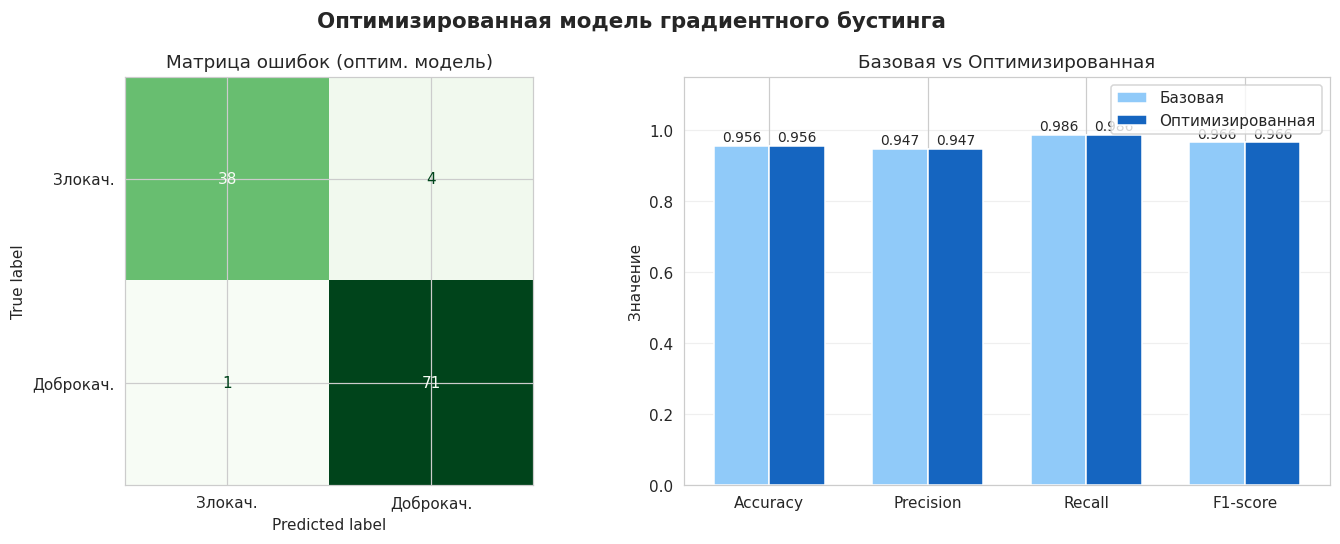

In [16]:
# Матрица ошибок + сравнение метрик
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Оптимизированная модель градиентного бустинга', fontsize=14, fontweight='bold')

# Матрица ошибок
cm_best = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm_best, display_labels=['Злокач.', 'Доброкач.']).plot(
    ax=axes[0], colorbar=False, cmap='Greens'
)
axes[0].set_title('Матрица ошибок (оптим. модель)')

# Сравнение метрик
x_pos = np.arange(4)
width = 0.35
b1 = axes[1].bar(x_pos - width/2, [acc_base, prec_base, rec_base, f1_base],
                  width, label='Базовая', color='#90CAF9', edgecolor='white')
b2 = axes[1].bar(x_pos + width/2, [acc_best, prec_best, rec_best, f1_best],
                  width, label='Оптимизированная', color='#1565C0', edgecolor='white')
for bar in list(b1) + list(b2):
    axes[1].text(
        bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
        f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9
    )
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1-score'])
axes[1].set_ylim(0, 1.15)
axes[1].set_title('Базовая vs Оптимизированная')
axes[1].set_ylabel('Значение')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Исследование влияния learning_rate и n_estimators

In [17]:
# Влияние learning_rate (n_estimators=100)
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]
lr_train_scores, lr_test_scores = [], []

for lr in learning_rates:
    m = GradientBoostingClassifier(n_estimators=100, learning_rate=lr, random_state=42)
    m.fit(X_train_sc, y_train)
    lr_train_scores.append(f1_score(y_train, m.predict(X_train_sc)))
    lr_test_scores.append(f1_score(y_test,  m.predict(X_test_sc)))

print('Влияние learning_rate (n_estimators=100):')
print(f'{"LR":<8} {"Train F1":>10} {"Test F1":>10}')
for lr, tr, te in zip(learning_rates, lr_train_scores, lr_test_scores):
    print(f'{lr:<8} {tr:>10.4f} {te:>10.4f}')

Влияние learning_rate (n_estimators=100):
LR         Train F1    Test F1
0.001        0.7703     0.7742
0.01         0.9896     0.9379
0.05         1.0000     0.9589
0.1          1.0000     0.9660
0.2          1.0000     0.9660
0.5          1.0000     0.9660
1.0          1.0000     0.9660


In [ ]:
# Влияние n_estimators (learning_rate=0.1)
n_est_range = [5, 10, 25, 50, 75, 100, 150, 200, 300, 500]
ne_train_scores, ne_test_scores = [], []

for n in n_est_range:
    m = GradientBoostingClassifier(n_estimators=n, learning_rate=0.1, random_state=42)
    m.fit(X_train_sc, y_train)
    ne_train_scores.append(f1_score(y_train, m.predict(X_train_sc)))
    ne_test_scores.append(f1_score(y_test,  m.predict(X_test_sc)))

print('Влияние n_estimators (learning_rate=0.1):')
print(f'{"N":>5} {"Train F1":>10} {"Test F1":>10}')
for n, tr, te in zip(n_est_range, ne_train_scores, ne_test_scores):
    print(f'{n:>5} {tr:>10.4f} {te:>10.4f}')

In [ ]:
# Визуализация влияния обоих гиперпараметров
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Влияние гиперпараметров на качество модели', fontsize=14, fontweight='bold')

# learning_rate
ax = axes[0]
ax.semilogx(learning_rates, lr_train_scores, 'o-', color='#1565C0', linewidth=2, label='Train F1')
ax.semilogx(learning_rates, lr_test_scores,  's--', color='#C62828', linewidth=2, label='Test F1')
ax.set_xlabel('Learning Rate (log scale)')
ax.set_ylabel('F1-score')
ax.set_title('Влияние learning_rate (n_estimators=100)')
ax.legend()
ax.grid(alpha=0.3)
ax.set_ylim(0.85, 1.02)

# n_estimators
ax = axes[1]
ax.plot(n_est_range, ne_train_scores, 'o-', color='#1565C0', linewidth=2, label='Train F1')
ax.plot(n_est_range, ne_test_scores,  's--', color='#C62828', linewidth=2, label='Test F1')
ax.set_xlabel('n_estimators')
ax.set_ylabel('F1-score')
ax.set_title('Влияние n_estimators (learning_rate=0.1)')
ax.legend()
ax.grid(alpha=0.3)
ax.set_ylim(0.85, 1.02)

plt.tight_layout()
plt.show()

In [ ]:
# Тепловая карта: learning_rate × n_estimators
lr_vals = [0.01, 0.05, 0.1, 0.2, 0.5]
ne_vals = [50, 100, 150, 200, 300]

heat_data = np.zeros((len(lr_vals), len(ne_vals)))
for i, lr in enumerate(lr_vals):
    for j, ne in enumerate(ne_vals):
        m = GradientBoostingClassifier(n_estimators=ne, learning_rate=lr, random_state=42)
        scores = cross_val_score(m, X_train_sc, y_train, cv=5, scoring='f1')
        heat_data[i, j] = scores.mean()

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    heat_data, ax=ax,
    xticklabels=ne_vals, yticklabels=lr_vals,
    annot=True, fmt='.3f', cmap='YlOrRd',
    linewidths=0.5, annot_kws={'size': 10},
    vmin=0.93, vmax=1.0
)
ax.set_xlabel('n_estimators', fontsize=12)
ax.set_ylabel('learning_rate', fontsize=12)
ax.set_title('F1-score (5-fold CV): learning_rate × n_estimators', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

best_idx = np.unravel_index(np.argmax(heat_data), heat_data.shape)
print(f'\nЛучшая комбинация: learning_rate={lr_vals[best_idx[0]]}, n_estimators={ne_vals[best_idx[1]]}')
print(f'F1 (CV) = {heat_data[best_idx]:.4f}')

## 7.1 Важность признаков

In [ ]:
# Важность признаков оптимизированной модели
importances = gb_best.feature_importances_
feat_df = pd.DataFrame({
    'feature': data.feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).reset_index(drop=True)

print('Топ-10 наиболее важных признаков:')
print(feat_df.head(10).to_string(index=False))

In [ ]:
# Визуализация важности признаков
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Важность признаков (оптимизированная модель)', fontsize=14, fontweight='bold')

# Горизонтальная гистограмма
palette = ['#1565C0' if i < 5 else '#90CAF9' for i in range(len(feat_df))]
axes[0].barh(feat_df['feature'][::-1], feat_df['importance'][::-1],
             color=palette[::-1], edgecolor='white')
axes[0].axvline(x=0.05, color='red', linestyle='--', alpha=0.7, label='Порог 5%')
axes[0].set_xlabel('Важность признака')
axes[0].set_title('Важность всех признаков')
axes[0].legend()
axes[0].grid(axis='x', alpha=0.3)
axes[0].tick_params(axis='y', labelsize=8)

# Топ-8 признаков: круговая диаграмма
top8 = feat_df.head(8)
other_val = feat_df['importance'][8:].sum()
labels_pie = list(top8['feature']) + ['Остальные']
sizes_pie  = list(top8['importance']) + [other_val]
colors_pie = plt.cm.tab10(np.linspace(0, 0.9, len(labels_pie)))
wedges, _, autotexts = axes[1].pie(
    sizes_pie, labels=None, autopct='%1.1f%%',
    colors=colors_pie, startangle=90, pctdistance=0.82
)
for at in autotexts:
    at.set_fontsize(8)
axes[1].legend(
    wedges, [f.replace(' ', '\n') for f in labels_pie],
    loc='lower left', fontsize=7,
    title='Признаки', bbox_to_anchor=(-0.15, -0.1)
)
axes[1].set_title('Доля топ-8 признаков')

plt.tight_layout()
plt.show()

## 8. Итоговые выводы

In [ ]:
# Итоговая сводная таблица
summary = pd.DataFrame({
    'Метрика':    ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Базовая':    [acc_base,  prec_base,  rec_base,  f1_base],
    'Оптим.':     [acc_best,  prec_best,  rec_best,  f1_best],
    'Прирост':    [acc_best-acc_base, prec_best-prec_base,
                   rec_best-rec_base, f1_best-f1_base]
})
summary = summary.round(4)
print('=== ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ===')
print(summary.to_string(index=False))

print('\n=== ЛУЧШИЕ ГИПЕРПАРАМЕТРЫ (GridSearchCV) ===')
for k, v in grid_search.best_params_.items():
    print(f'  {k}: {v}')

print('\n=== ТОП-5 ПРИЗНАКОВ ===')
print(feat_df[['feature','importance']].head(5).to_string(index=False))